In [63]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, pm4py

log = pm4py.read_xes('data/BPIC17.xes.gz') 

parsing log, completed traces :: 100%|██████████| 31509/31509 [00:21<00:00, 1441.00it/s]


In [54]:
#print(log)
df = log.sort_values(["case:concept:name", "time:timestamp"])
print(df.shape)
print(df["EventOrigin"].value_counts())
print(df["lifecycle:transition"].value_counts())

df.head()
print(f"Amount of Activities: {df['case:concept:name'].nunique()}")
print(f"Amount of Cases: {df['concept:name'].nunique()}")

#df = df.sample(frac=0.01)
#print(df)

wf = df[df["EventOrigin"] == "Workflow"]

# all lifecycle values for workflow events, with counts
print(wf["lifecycle:transition"].value_counts(dropna=False))
print(wf["concept:name"].value_counts(dropna=False))

# per activity: which lifecycle values does each W_ activity have?
print(pd.crosstab(wf["concept:name"], wf["lifecycle:transition"]))

(1202267, 19)
EventOrigin
Workflow       768823
Application    239595
Offer          193849
Name: count, dtype: int64
lifecycle:transition
complete     475306
suspend      215402
schedule     149104
start        128227
resume       127160
ate_abort     85224
withdraw      21844
Name: count, dtype: int64
Amount of Activities: 31509
Amount of Cases: 26
lifecycle:transition
suspend      215402
schedule     149104
start        128227
resume       127160
ate_abort     85224
complete      41862
withdraw      21844
Name: count, dtype: int64
concept:name
W_Validate application        209496
W_Call after offers           191092
W_Call incomplete files       168529
W_Complete application        148900
W_Handle leads                 47264
W_Assess potential fraud        3282
W_Shortened completion           238
W_Personal Loan collection        22
Name: count, dtype: int64
lifecycle:transition        ate_abort  complete  resume  schedule  start  \
concept:name                                     

In [55]:
cid, act = "case:concept:name", "concept:name"

# 1) A_/O_ lifecycle values (expect only 'complete')
ao = df[df["EventOrigin"].isin(["Application", "Offer"])]
print(ao["lifecycle:transition"].value_counts(dropna=False))


# 2) share of events per origin
print(df["EventOrigin"].value_counts(normalize=True).round(3))

# 3) evidence for the report: variants with vs without W_ events
v_all = len(pm4py.get_variants(df))
v_ao = len(pm4py.get_variants(ao))
print("variants with W_:", v_all, "| without W_:", v_ao)

# 4) work items per case and suspend/resume cycles per case (workload of W_)
wf = df[df["EventOrigin"] == "Workflow"]
per_case = wf.groupby(cid).size()
print("W_ events per case:\n", per_case.describe().round(1))

lifecycle:transition
complete    433444
Name: count, dtype: int64
EventOrigin
Workflow       0.639
Application    0.199
Offer          0.161
Name: proportion, dtype: float64
variants with W_: 15930 | without W_: 2630
W_ events per case:
 count    31509.0
mean        24.4
std         13.7
min          3.0
25%         14.0
50%         21.0
75%         31.0
max        151.0
dtype: float64


In [56]:
import pandas as pd

w = log[log["EventOrigin"] == "Workflow"]
t = pd.crosstab(w["concept:name"], w["lifecycle:transition"])[["start", "complete", "ate_abort", "withdraw"]]
t["complete / start"] = (t["complete"] / t["start"]).round(2)
print(t.to_string())

lifecycle:transition        start  complete  ate_abort  withdraw  complete / start
concept:name                                                                      
W_Assess potential fraud      355       282         42         3              0.79
W_Call after offers         31485       342      31085      3176              0.01
W_Call incomplete files     23218      2793      20220         0              0.12
W_Complete application      29918     19104      10565      1863              0.64
W_Handle leads               3727      3493        151     16802              0.94
W_Personal Loan collection      4         0          0         0              0.00
W_Shortened completion         76         0          0         0              0.00
W_Validate application      39444     15848      23161         0              0.40


In [57]:
import numpy as np, pandas as pd, pm4py
cid, act, ts = "case:concept:name", "concept:name", "time:timestamp"

cases = log.groupby(cid).agg(start=(ts, "min"), end=(ts, "max"), length=(act, "size"))
cases["dur_s"] = (cases["end"] - cases["start"]).dt.total_seconds()
cases["dur_m"] = cases["dur_s"] / 60
cases["dur_d"] = cases["dur_s"] / 86400

case_labels  = [c for c in log.columns if c.startswith("case:") and c != cid]
event_labels = [c for c in log.columns if not c.startswith("case:")]
cat_attrs    = [c for c in event_labels
                if not pd.api.types.is_numeric_dtype(log[c]) or log[c].nunique() <= 10]

variants = pm4py.get_variants(log)
counts   = np.sort(np.array(list(variants.values())))[::-1]
coverage = np.cumsum(counts) / counts.sum()

acc = log["Accepted"].dropna()
req = log.drop_duplicates(cid)["case:RequestedAmount"]

stats = pd.Series({
    "cases":                    len(cases),
    "events":                   len(log),
    "variants":                 len(variants),
    "distinct case labels":     len(case_labels),
    "distinct event labels":    len(event_labels),
    "categorical event attrs":  len(cat_attrs),
    "case length mean":         round(cases["length"].mean(), 2),
    "case length std":          round(cases["length"].std(), 2),
    "duration mean (days)":     round(cases["dur_d"].mean(), 2),
    "duration std (days)":      round(cases["dur_d"].std(), 2),
    "duration mean (min)":      round(cases["dur_m"].mean(), 2),
    "duration std (min)":       round(cases["dur_m"].std(), 2),
    "duration mean (sec)":      round(cases["dur_s"].mean(), 2),
    "duration std (sec)":       round(cases["dur_s"].std(), 2),
    "top-10 variant coverage":  round(coverage[9], 3),
    "top-100 variant coverage": round(coverage[99], 3),
    "offers accepted":          round((acc == "True").mean(), 3),
    "requested amount Q1":      int(req.quantile(0.25)),
    "requested amount median":  int(req.median()),
    "requested amount Q3":      int(req.quantile(0.75)),
})
print(stats.to_string())
print("\ncase labels:       ", case_labels)
print("event labels:      ", event_labels)
print("categorical attrs: ", cat_attrs)
print("\nevent origin:\n", log["EventOrigin"].value_counts())

cases                         31509.000
events                      1202267.000
variants                      15930.000
distinct case labels              3.000
distinct event labels            15.000
categorical event attrs          10.000
case length mean                 38.160
case length std                  16.720
duration mean (days)             21.900
duration std (days)              13.170
duration mean (min)           31535.430
duration std (min)            18963.690
duration mean (sec)         1892125.920
duration std (sec)          1137821.690
top-10 variant coverage           0.153
top-100 variant coverage          0.307
offers accepted                   0.000
requested amount Q1            6000.000
requested amount median       12500.000
requested amount Q3           21000.000

case labels:        ['case:LoanGoal', 'case:ApplicationType', 'case:RequestedAmount']
event labels:       ['Action', 'org:resource', 'concept:name', 'EventOrigin', 'EventID', 'lifecycle:transition', 

                        cases  share
concept:name                        
Accepted (A_Pending)    17228  0.547
Cancelled               10431  0.331
Denied                   3752  0.119
Missing (no end state)     98  0.003


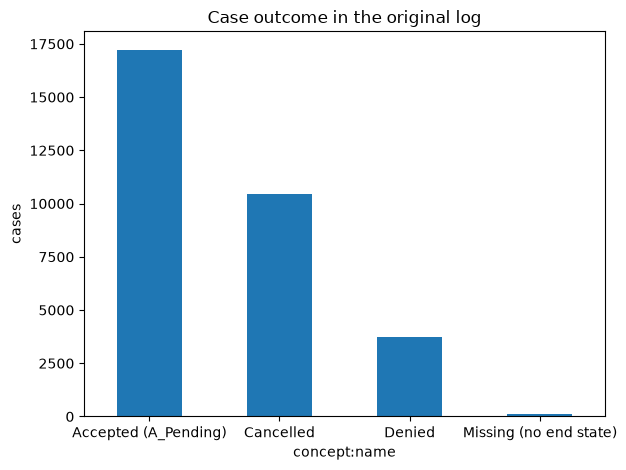

In [58]:
end_acts = {"A_Pending": "Accepted (A_Pending)", "A_Denied": "Denied", "A_Cancelled": "Cancelled"}

ends = log[log[act].isin(end_acts)].sort_values(ts)
outcome = ends.groupby(cid)[act].last().map(end_acts)
outcome = outcome.reindex(log[cid].unique()).fillna("Missing (no end state)")

t = outcome.value_counts().to_frame("cases")
t["share"] = (t["cases"] / t["cases"].sum()).round(3)
print(t.to_string())

t["cases"].plot.bar(title="Case outcome in the original log", ylabel="cases", rot=0)
plt.tight_layout(); plt.show()

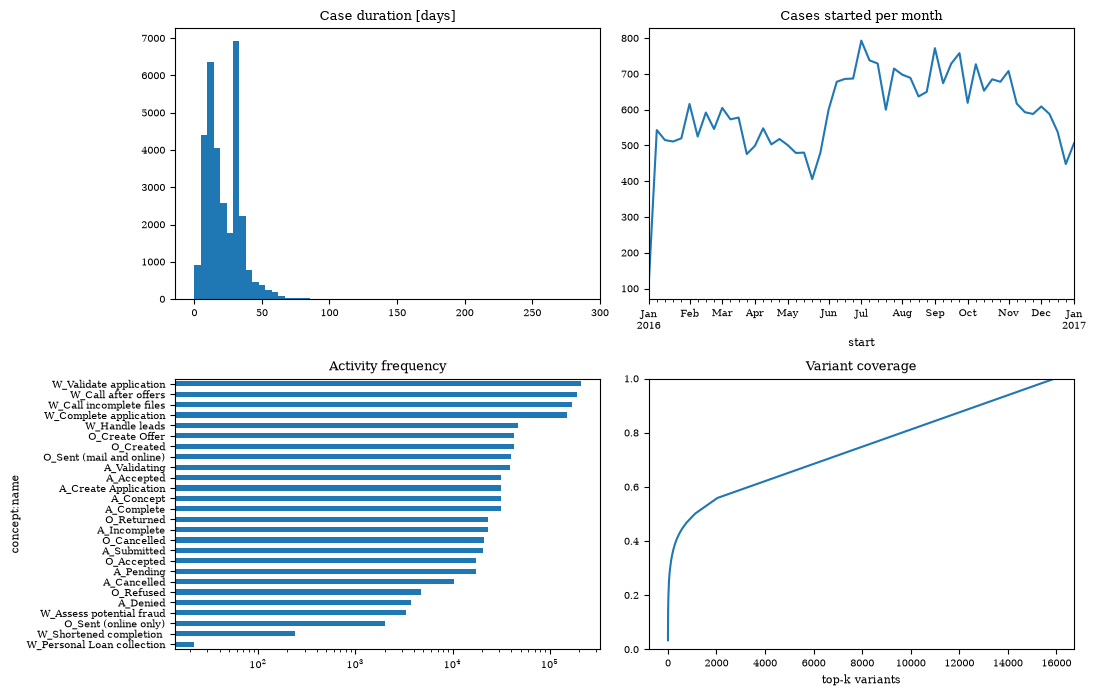

cases: 31509 | variants: 15930 | top-10 coverage: 0.153
      dur_days  length
mean     21.90   38.16
std      13.17   16.72


In [62]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, pm4py
cid, act, ts = "case:concept:name", "concept:name", "time:timestamp"
g = df.groupby(cid)[ts]
cases = pd.DataFrame({"start": g.min(), "dur_days": (g.max() - g.min()).dt.total_seconds() / 86400,
                      "length": df.groupby(cid).size()})
variants = pm4py.get_variants(df)
counts = np.sort(np.array(list(variants.values())))[::-1]

fig, ax = plt.subplots(2, 2, figsize=(11, 7))
ax[0, 0].hist(cases["dur_days"], bins=60); ax[0, 0].set(title="Case duration [days]")
cases.groupby(cases["start"].dt.tz_localize(None).dt.to_period("W")).size().plot(ax=ax[0, 1], title="Cases started per month")
df[act].value_counts().sort_values().plot.barh(ax=ax[1, 0], logx=True, title="Activity frequency")
ax[1, 1].plot(np.cumsum(counts) / counts.sum()); ax[1, 1].set(title="Variant coverage", xlabel="top-k variants", ylim=(0, 1))
plt.tight_layout(); plt.show()

print("cases:", len(cases), "| variants:", len(variants),
      "| top-10 coverage:", round(counts[:10].sum() / counts.sum(), 3))
print(cases[["dur_days", "length"]].agg(["mean", "std"]).round(2))

A_Pending + O_Accepted: 17228 cases with A_Pending, 17228 with a partner, 17228 within 2 min (100.0% of the partners), median gap 0.00 s
A_Denied + O_Refused: 3752 cases with A_Denied, 3720 with a partner, 3720 within 2 min (100.0% of the partners), median gap 0.03 s
A_Cancelled + O_Cancelled: 10431 cases with A_Cancelled, 10431 with a partner, 10383 within 2 min (99.5% of the partners), median gap 0.03 s


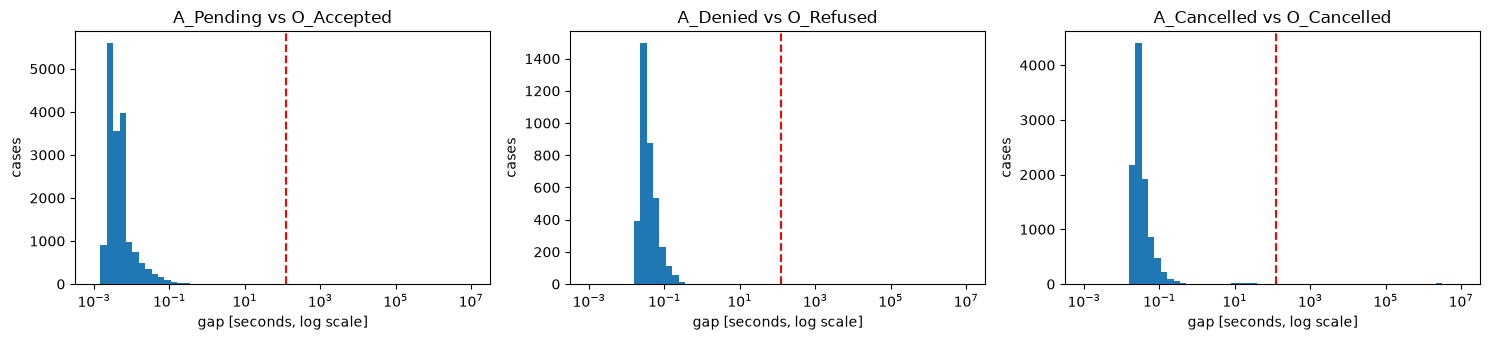

In [19]:
import numpy as np, matplotlib.pyplot as plt
#Validation of the Approach done by the Competition Winner, how long events are seperated 
ao = log[log["EventOrigin"].isin(["Application", "Offer"])]
pairs = [("A_Pending", "O_Accepted"), ("A_Denied", "O_Refused"), ("A_Cancelled", "O_Cancelled")]

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, (a, o) in zip(axes, pairs):
    t_a = ao[ao[act] == a].groupby(cid)[ts].max()                 # end event time per case
    po = ao[(ao[act] == o) & ao[cid].isin(t_a.index)]
    gap = (po[ts] - po[cid].map(t_a)).abs().dt.total_seconds()
    gap = gap.groupby(po[cid]).min().clip(lower=0.001)            # closest partner per case
    print(f"{a} + {o}: {len(t_a)} cases with {a}, {len(gap)} with a partner, "
          f"{(gap < 120).sum()} within 2 min ({(gap < 120).mean():.1%} of the partners), "
          f"median gap {gap.median():.2f} s")
    ax.hist(gap, bins=np.logspace(-3, 7, 60))
    ax.set_xscale("log"); ax.axvline(120, color="r", ls="--")
    ax.set(title=f"{a} vs {o}", xlabel="gap [seconds, log scale]", ylabel="cases")
plt.tight_layout(); plt.show()

In [20]:
import pandas as pd, pm4py

cid, act, ts = "case:concept:name", "concept:name", "time:timestamp"
funnel = []
def log_step(name, x):
    funnel.append({"step": name, "cases": x[cid].nunique(), "events": len(x),
                   "variants": len(pm4py.get_variants(x))})
    
log_step("Beginning", log)

# 1) alle Events mit lifecycle "complete" (A_/O_ sind immer complete, dazu fertige W_-Events)
df =(log[log["lifecycle:transition"] == "complete"]
     .sort_values([cid, ts], kind="stable").reset_index(drop=True))
log_step("1 nur complete Events", df)

# 5) Stichprobe ganzer Cases (feste Seed) aus dem bereinigten df
ids = pd.Series(df[cid].unique()).sample(1500, random_state=42)
df_s = df[df[cid].isin(ids)]
print("sample:", df_s[cid].nunique(), "cases,", len(df_s), "events")

sample: 1500 cases, 22601 events


replaying log with TBR, completed traces :: 100%|██████████| 573/573 [00:00<00:00, 1256.20it/s]

Inductive nt=0.0       done in 5s



replaying log with TBR, completed traces :: 100%|██████████| 573/573 [00:00<00:00, 1333.48it/s]

Inductive nt=0.1       done in 4s



replaying log with TBR, completed traces :: 100%|██████████| 573/573 [00:00<00:00, 1431.99it/s]

Inductive nt=0.2       done in 2s


... (6 outputs left out)


replaying log with TBR, completed traces :: 100%|██████████| 573/573 [00:00<00:00, 903.59it/s] 

Heuristics dep=0.5     done in 2s



replaying log with TBR, completed traces :: 100%|██████████| 573/573 [00:00<00:00, 1221.43it/s]

Heuristics dep=0.9     done in 2s
                    cases_tbr  fit_tbr  prec_etc  generalization  simp_arc_degree   size  XOR_places   CFC  sec
Inductive nt=0.0        1.000    1.000     0.258           0.893            0.626  114.0        22.0  55.0  5.0
Inductive nt=0.1        0.872    0.996     0.344           0.927            0.658  100.0        21.0  46.0  4.0
Inductive nt=0.2        0.624    0.981     0.312           0.901            0.659   81.0        14.0  36.0  2.0
Inductive nt=0.5        0.054    0.895     0.581           0.845            0.677   63.0        10.0  24.0  2.0
Inductive nt=0.9        0.009    0.862     0.689           0.853            0.684   52.0         9.0  20.0  1.0
Heuristics dep=0.2      0.000    0.854     0.970           0.772            0.516  126.0        19.0  79.0  2.0
Heuristics dep=0.5      0.000    0.855     0.970           0.784            0.514  127.0        19.0  80.0  2.0
Heuristics dep=0.9      0.000    0.862     0.963           0.845      

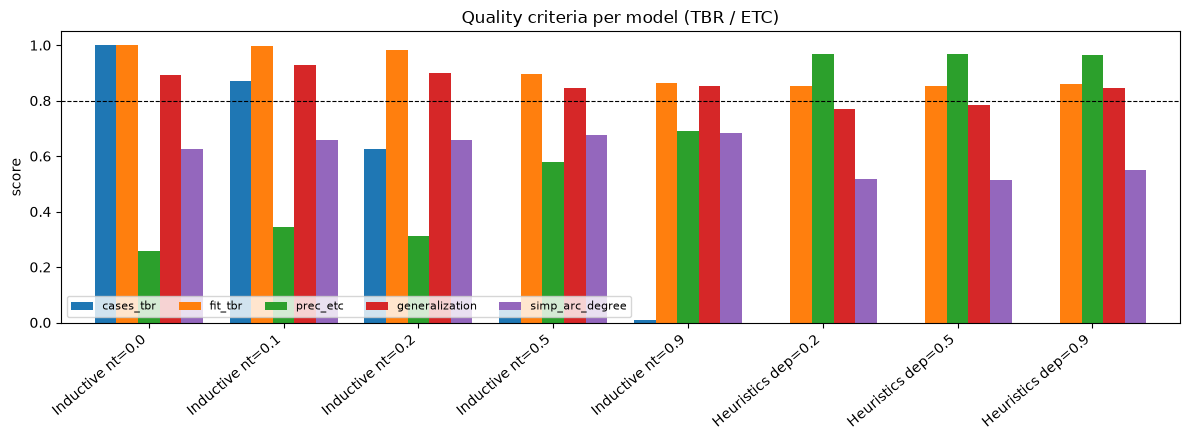

In [21]:
import time, warnings
import pandas as pd, pm4py, matplotlib.pyplot as plt
from pm4py.algo.evaluation.generalization import algorithm as gen_alg
from pm4py.algo.evaluation.simplicity import algorithm as simp_alg
warnings.filterwarnings("ignore")

models = {}
for nt in [0.0, 0.1, 0.2, 0.5, 0.9]:
    models[f"Inductive nt={nt}"] = pm4py.discover_petri_net_inductive(df_s, noise_threshold=nt)
for dep in [0.2, 0.5, 0.9]:
    models[f"Heuristics dep={dep}"] = pm4py.discover_petri_net_heuristics(df_s, dependency_threshold=dep)

rows = {}
try:
    for name, (net, im, fm) in models.items():
        t0 = time.time()
        try:
            tb = pm4py.fitness_token_based_replay(df_s, net, im, fm)
            n = len(net.places) + len(net.transitions)
            rows[name] = {"cases_tbr": tb["perc_fit_traces"] / 100, 
                          "fit_tbr": tb["log_fitness"],
                          "prec_etc": pm4py.precision_token_based_replay(df_s, net, im, fm),
                          "generalization": gen_alg.apply(df_s, net, im, fm),
                          "simp_arc_degree": simp_alg.apply(net), 
                          "size": n,
                          "XOR_places": sum(len(p.out_arcs) > 1 for p in net.places),
                          "CFC": sum(len(p.out_arcs) for p in net.places if len(p.out_arcs) > 1) + sum(len(t.out_arcs) > 1 for t in net.transitions),
                          #"sound": pm4py.check_soundness(net, im, fm)[0],
                          "sec": round(time.time() - t0)}
            print(f"{name:22s} done in {rows[name]['sec']}s", flush=True)
        except Exception as e:
            print(f"{name:22s} FAILED: {type(e).__name__} {e}", flush=True)
except KeyboardInterrupt:
    print("interrupted, showing the models that finished")

res = pd.DataFrame(rows).T
print(res.round(3).to_string())

cols = ["cases_tbr", "fit_tbr", "prec_etc", "generalization", "simp_arc_degree"]
ax = res[cols].astype(float).plot.bar(figsize=(12, 4.5), width=0.8, title="Quality criteria per model (TBR / ETC)")
ax.axhline(0.8, color="k", ls="--", lw=0.8)
ax.set(ylim=(0, 1.05), ylabel="score")
plt.xticks(rotation=40, ha="right"); plt.legend(loc="lower left", ncol=5, fontsize=8)
plt.tight_layout(); plt.show()

In [60]:
net1, im1, fm1 = pm4py.discover_petri_net_inductive(df_s, 0.5)
pm4py.save_vis_petri_net(net1, im1, fm1, "petrinet nt05.pdf")

net1, im1, fm1 = pm4py.discover_petri_net_heuristics(df_s, 0.9)
pm4py.save_vis_petri_net(net1, im1, fm1, "petrinet dep09.pdf")


''

In [22]:
import time, pandas as pd, pm4py
from pm4py.algo.evaluation.generalization import algorithm as gen_alg
from pm4py.algo.evaluation.simplicity import algorithm as simp_alg


def evaluate(data, name, nt=0.0, align=False, train=None):
    t0 = time.time()
    net, im, fm = pm4py.discover_petri_net_inductive(data if train is None else train, noise_threshold=nt)
    tb = pm4py.fitness_token_based_replay(data, net, im, fm)
    row = {"cases_tbr": tb["perc_fit_traces"] / 100,
           "fit_tbr": tb["log_fitness"],
           "prec_etc": pm4py.precision_token_based_replay(data, net, im, fm),
           "generalization": gen_alg.apply(data, net, im, fm),
           "simp_arc_degree": simp_alg.apply(net),
           "size": len(net.places) + len(net.transitions),
           "XOR_places": sum(len(p.out_arcs) > 1 for p in net.places),
           "CFC": sum(len(p.out_arcs) for p in net.places if len(p.out_arcs) > 1)
                  + sum(len(t.out_arcs) > 1 for t in net.transitions)}
    if align:
        al = pm4py.fitness_alignments(data, net, im, fm)
        row["cases_align"] = al["percFitTraces"] / 100
        row["fit_align"] = al["averageFitness"]
        row["prec_align"] = pm4py.precision_alignments(data, net, im, fm)
    row["sec"] = round(time.time() - t0)
    results[name] = row
    print(pd.DataFrame(results).T.round(3).to_string())
    return net, im, fm

# after each cleaning step:


In [23]:
# 2) nur Cases mit Endzustand
results = {}
df1 = df

ids_end = df.loc[df[act].isin(["A_Pending", "A_Denied", "A_Cancelled"]), cid].unique()
df = df[df[cid].isin(ids_end)].reset_index(drop=True)
log_step("2 nur Cases mit Endzustand", df)
df2 = df



# 3) Endzustand zusammenfassen: zugehoerige O_-Events (max. 2 min vom Endzustand) loeschen, Endzustand umbenennen
END = {"A_Pending": ("Pending", "O_Accepted"),
       "A_Denied": ("Denied", "O_Refused"),
       "A_Cancelled": ("Cancelled", "O_Cancelled")}
for a_name, (new, o_name) in END.items():
    t_end = df.loc[df[act] == a_name].groupby(cid)[ts].max()        # Zeitpunkt des Endzustands pro Case
    t = df[cid].map(t_end)
    drop = (df[act] == o_name) & t.notna() & ((df[ts] - t).abs() < pd.Timedelta("2min"))
    df.loc[df[act] == a_name, act] = new
    df = df[~drop].reset_index(drop=True)
log_step("3 Endzustand zusammengefasst", df)

df3 = df

# 4) direkt aufeinanderfolgende gleiche Aktivitaeten zusammenfassen
df = df[df[act] != df.groupby(cid)[act].shift()].reset_index(drop=True)
log_step("4 Wiederholungen zusammengefasst", df)

df4 = df

# evidence: what happens after the end state?
is_end = df[act].isin(["Pending", "Denied", "Cancelled"])          # the end state event itself
after_end = is_end.groupby(df[cid]).cummax() & ~is_end              # every event after it in the same case
tail = df[after_end]
print("cases with events after the end state:", tail[cid].nunique())
print(tail[act].value_counts().to_string())

# check: does anything "real" start again after the end state?
for a in ["O_Create Offer", "A_Validating", "A_Incomplete"]:
    print(f"{a} after end state: {tail.loc[tail[act] == a, cid].nunique()} cases")

# cut everything after the end state
df = df[~after_end].reset_index(drop=True)
log_step("5 events after end state removed", df)
print(pd.DataFrame(funnel).to_string(index=False))
print(df.groupby(cid)[act].last().value_counts())
df5 = df 


evaluate(df1, "1 lifecycle filter")
evaluate(df1, "1 lifecycle filter 0.1", 0.1)
evaluate(df2, "2 end state only")
evaluate(df2, "2 end state only 0.1", 0.1)
evaluate(df3, "3 end merged")
evaluate(df3, "3 end merged 0.1", 0.1)
evaluate(df4, "4 repeats merged")
evaluate(df4, "4 repeats merged 0.1", 0.1)
evaluate(df5, "5 tail cut")
evaluate(df5, "5 tail cut 0.1", 0.1)

cases with events after the end state: 9395
concept:name
W_Validate application      4925
O_Cancelled                 4436
W_Call incomplete files      650
W_Call after offers          135
W_Assess potential fraud      93
W_Complete application        63
O_Create Offer after end state: 0 cases
A_Validating after end state: 0 cases
A_Incomplete after end state: 0 cases
                            step  cases  events  variants
                       Beginning  31509 1202267     15930
           1 nur complete Events  31509  475306      5623
      2 nur Cases mit Endzustand  31411  473963      5562
    3 Endzustand zusammengefasst  31411  438881      5527
4 Wiederholungen zusammengefasst  31411  433965      5412
5 events after end state removed  31411  423663      4779
concept:name
Pending      17228
Cancelled    10431
Denied        3752
Name: count, dtype: int64


replaying log with TBR, completed traces :: 100%|██████████| 5623/5623 [00:06<00:00, 905.09it/s] 


                    cases_tbr  fit_tbr  prec_etc  generalization  simp_arc_degree  size  XOR_places   CFC   sec
1 lifecycle filter        1.0      1.0     0.293           0.976            0.617  87.0        16.0  42.0  64.0


replaying log with TBR, completed traces :: 100%|██████████| 5623/5623 [00:03<00:00, 1495.96it/s]


                        cases_tbr  fit_tbr  prec_etc  generalization  simp_arc_degree  size  XOR_places   CFC   sec
1 lifecycle filter          1.000    1.000     0.293           0.976            0.617  87.0        16.0  42.0  64.0
1 lifecycle filter 0.1      0.922    0.998     0.392           0.990            0.645  69.0        15.0  35.0  37.0


replaying log with TBR, completed traces :: 100%|██████████| 5562/5562 [00:05<00:00, 1081.13it/s]


... (12 outputs left out)

                        cases_tbr  fit_tbr  prec_etc  generalization  simp_arc_degree  size  XOR_places   CFC   sec
1 lifecycle filter          1.000    1.000     0.293           0.976            0.617  87.0        16.0  42.0  64.0
1 lifecycle filter 0.1      0.922    0.998     0.392           0.990            0.645  69.0        15.0  35.0  37.0
2 end state only            1.000    1.000     0.293           0.959            0.617  87.0        16.0  42.0  62.0
2 end state only 0.1        0.922    0.998     0.392           0.990            0.645  69.0        15.0  35.0  36.0
3 end merged                1.000    1.000     0.303           0.959            0.606  77.0        14.0  38.0  53.0
3 end merged 0.1            0.885    0.991     0.398           0.969            0.649  96.0        22.0  47.0  37.0
4 repeats merged            1.000    1.000     0.307           0.958            0.600  72.0        13.0  36.0  47.0
4 repeats merged 0.1        0.885    0.991     0.404           0.966    

replaying log with TBR, completed traces :: 100%|██████████| 4779/4779 [00:03<00:00, 1408.63it/s]

                        cases_tbr  fit_tbr  prec_etc  generalization  simp_arc_degree  size  XOR_places   CFC   sec
1 lifecycle filter          1.000    1.000     0.293           0.976            0.617  87.0        16.0  42.0  64.0
1 lifecycle filter 0.1      0.922    0.998     0.392           0.990            0.645  69.0        15.0  35.0  37.0
2 end state only            1.000    1.000     0.293           0.959            0.617  87.0        16.0  42.0  62.0
2 end state only 0.1        0.922    0.998     0.392           0.990            0.645  69.0        15.0  35.0  36.0
3 end merged                1.000    1.000     0.303           0.959            0.606  77.0        14.0  38.0  53.0
3 end merged 0.1            0.885    0.991     0.398           0.969            0.649  96.0        22.0  47.0  37.0
4 repeats merged            1.000    1.000     0.307           0.958            0.600  72.0        13.0  36.0  47.0
4 repeats merged 0.1        0.885    0.991     0.404           0.966    

(places: [ p_10, p_11, p_12, p_13, p_14, p_16, p_17, p_18, p_19, p_20, p_21, p_22, p_23, p_25, p_26, p_27, p_28, p_3, p_32, p_33, p_37, p_38, p_4, p_40, p_41, p_42, p_43, p_46, p_47, p_5, p_6, p_7, p_9, sink, source ]
 transitions: [ (0f274dac-ff92-41af-a6e6-80f803b6cc45, 'W_Assess potential fraud'), (0ffaf272-fb3c-4733-8829-5f49b872fb5e, 'A_Submitted'), (1a5c9c65-0754-41f5-b3bc-39c9ddc92dfc, 'Cancelled'), (2574d4a5-ea18-4f56-ad9c-755d855b2588, 'W_Complete application'), (26b1807a-2e1a-4b67-8da4-26db4a1d1526, 'W_Validate application'), (28629298-6260-413b-b116-37824806da34, 'A_Create Application'), (36cdda11-f58c-4f17-af8e-321b44a0a6e5, 'O_Created'), (3c7d7115-07c9-43c2-9c3f-a954a5e0a0b8, 'A_Complete'), (4cf8b8c6-eef3-43be-844e-caadf6a5bec9, 'A_Validating'), (525f6b02-ea18-4130-a4e6-5e5c5c0ef143, 'W_Handle leads'), (53c3acd9-3158-41b3-bd24-cd3cd1b009f2, 'A_Accepted'), (9c074c66-83ee-4c09-9588-286c8281712e, 'O_Sent (mail and online)'), (9ec04cf3-e007-4d46-9df9-632e43b67895, 'A_Incomplet

In [24]:
for k in [20, 30, 35, 40, 50, 75, 100, 150]:
    results = {}
    evaluate(df, f"top-{k}", nt=0.0, train=pm4py.filter_variants_top_k(df, k))
    evaluate(df, f"top-{k}", nt=0.1, train=pm4py.filter_variants_top_k(df, k))

replaying log with TBR, completed traces :: 100%|██████████| 4779/4779 [00:02<00:00, 2193.45it/s]


        cases_tbr  fit_tbr  prec_etc  generalization  simp_arc_degree  size  XOR_places   CFC   sec
top-20      0.646    0.966     0.839           0.992            0.706  48.0         9.0  19.0  17.0


replaying log with TBR, completed traces :: 100%|██████████| 4779/4779 [00:01<00:00, 2549.62it/s]


        cases_tbr  fit_tbr  prec_etc  generalization  simp_arc_degree  size  XOR_places   CFC   sec
top-20      0.692    0.974     0.821           0.951            0.724  42.0         8.0  17.0  16.0


replaying log with TBR, completed traces :: 100%|██████████| 4779/4779 [00:02<00:00, 2069.56it/s]


        cases_tbr  fit_tbr  prec_etc  generalization  simp_arc_degree  size  XOR_places   CFC   sec
top-30      0.731    0.976     0.694           0.992            0.692  54.0        10.0  22.0  19.0


... (22 outputs left out)

replaying log with TBR, completed traces :: 100%|██████████| 4779/4779 [00:02<00:00, 1991.43it/s]


         cases_tbr  fit_tbr  prec_etc  generalization  simp_arc_degree  size  XOR_places   CFC   sec
top-150      0.934    0.995     0.568           0.991             0.66  62.0        12.0  28.0  22.0


replaying log with TBR, completed traces :: 100%|██████████| 4779/4779 [00:02<00:00, 1683.53it/s]


         cases_tbr  fit_tbr  prec_etc  generalization  simp_arc_degree  size  XOR_places   CFC   sec
top-150      0.714    0.982     0.681           0.939            0.684  65.0        13.0  28.0  20.0


In [25]:
results = {}
for k in [35, 40, 50, 75]:
    evaluate(df, f"top-{k}", nt=0.0, align=True, train=pm4py.filter_variants_top_k(df, k))

aligning log, completed variants :: 100%|██████████| 4779/4779 [01:01<00:00, 77.30it/s] 
computing precision with alignments, completed variants :: 100%|██████████| 15418/15418 [00:19<00:00, 806.11it/s] 


        cases_tbr  fit_tbr  prec_etc  generalization  simp_arc_degree  size  XOR_places   CFC  cases_align  fit_align  prec_align    sec
top-35      0.816    0.986     0.642           0.991            0.682  60.0        11.0  25.0        0.776      0.979        0.65  111.0


aligning log, completed variants :: 100%|██████████| 4779/4779 [01:01<00:00, 77.68it/s] 
computing precision with alignments, completed variants :: 100%|██████████| 15418/15418 [00:18<00:00, 812.00it/s]


        cases_tbr  fit_tbr  prec_etc  generalization  simp_arc_degree  size  XOR_places   CFC  cases_align  fit_align  prec_align    sec
top-35      0.816    0.986     0.642           0.991            0.682  60.0        11.0  25.0        0.776      0.979        0.65  111.0
top-40      0.816    0.986     0.642           0.991            0.682  60.0        11.0  25.0        0.776      0.979        0.65  110.0


aligning log, completed variants :: 100%|██████████| 4779/4779 [00:59<00:00, 79.71it/s] 
computing precision with alignments, completed variants :: 100%|██████████| 15418/15418 [00:21<00:00, 725.60it/s]


        cases_tbr  fit_tbr  prec_etc  generalization  simp_arc_degree  size  XOR_places   CFC  cases_align  fit_align  prec_align    sec
top-35      0.816    0.986     0.642           0.991            0.682  60.0        11.0  25.0        0.776      0.979        0.65  111.0
top-40      0.816    0.986     0.642           0.991            0.682  60.0        11.0  25.0        0.776      0.979        0.65  110.0
top-50      0.862    0.990     0.642           0.991            0.682  60.0        12.0  26.0        0.819      0.983        0.65  111.0


aligning log, completed variants :: 100%|██████████| 4779/4779 [01:10<00:00, 67.54it/s] 
computing precision with alignments, completed variants :: 100%|██████████| 15418/15418 [00:23<00:00, 664.87it/s]


        cases_tbr  fit_tbr  prec_etc  generalization  simp_arc_degree  size  XOR_places   CFC  cases_align  fit_align  prec_align    sec
top-35      0.816    0.986     0.642           0.991            0.682  60.0        11.0  25.0        0.776      0.979       0.650  111.0
top-40      0.816    0.986     0.642           0.991            0.682  60.0        11.0  25.0        0.776      0.979       0.650  110.0
top-50      0.862    0.990     0.642           0.991            0.682  60.0        12.0  26.0        0.819      0.983       0.650  111.0
top-75      0.908    0.994     0.631           0.991            0.677  63.0        12.0  27.0        0.861      0.987       0.643  125.0


In [26]:
for k in [35, 50, 100]:
    results = {}
    evaluate(df4, f"top-{k}", nt=0.0, train=pm4py.filter_variants_top_k(df4, k))
    evaluate(df4, f"top-{k}", nt=0.1, train=pm4py.filter_variants_top_k(df4, k))

replaying log with TBR, completed traces :: 100%|██████████| 5412/5412 [00:02<00:00, 1848.84it/s]


        cases_tbr  fit_tbr  prec_etc  generalization  simp_arc_degree  size  XOR_places   CFC   sec
top-35      0.721    0.977     0.625           0.991            0.663  67.0        13.0  29.0  24.0


replaying log with TBR, completed traces :: 100%|██████████| 5412/5412 [00:02<00:00, 2051.54it/s]


        cases_tbr  fit_tbr  prec_etc  generalization  simp_arc_degree  size  XOR_places   CFC   sec
top-35      0.517    0.947     0.715            0.96            0.687  57.0        10.0  22.0  20.0


replaying log with TBR, completed traces :: 100%|██████████| 5412/5412 [00:03<00:00, 1458.68it/s]


        cases_tbr  fit_tbr  prec_etc  generalization  simp_arc_degree  size  XOR_places   CFC   sec
top-50      0.811    0.987      0.58           0.991            0.675  79.0        15.0  34.0  28.0


... (2 outputs left out)

replaying log with TBR, completed traces :: 100%|██████████| 5412/5412 [00:03<00:00, 1696.24it/s]


         cases_tbr  fit_tbr  prec_etc  generalization  simp_arc_degree  size  XOR_places   CFC   sec
top-100      0.839    0.987     0.613           0.991            0.682  73.0        14.0  30.0  25.0


replaying log with TBR, completed traces :: 100%|██████████| 5412/5412 [00:02<00:00, 2074.37it/s]


         cases_tbr  fit_tbr  prec_etc  generalization  simp_arc_degree  size  XOR_places   CFC   sec
top-100      0.691    0.972     0.757           0.961              0.7  56.0        11.0  23.0  20.0


aligning log, completed variants :: 100%|██████████| 4779/4779 [01:01<00:00, 77.70it/s] 
computing precision with alignments, completed variants :: 100%|██████████| 15418/15418 [00:20<00:00, 748.68it/s]


              cases_tbr  fit_tbr  prec_etc  generalization  simp_arc_degree  size  XOR_places   CFC  cases_align  fit_align  prec_align    sec
FINAL top-50      0.862     0.99     0.642           0.991            0.682  60.0        12.0  26.0        0.819      0.983        0.65  112.0
final model sound: True


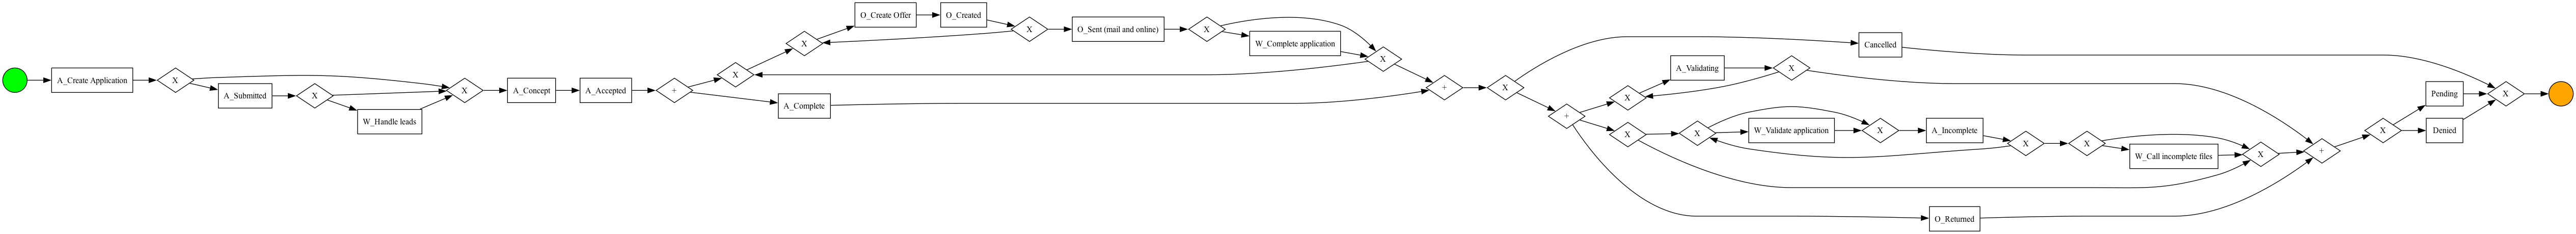

In [27]:
# Final Model 
K, NT = 50, 0.0          # set from your K table

results = {}
top = pm4py.filter_variants_top_k(df, K)
net, im, fm = evaluate(df, f"FINAL top-{K}", nt=NT, align=True, train=top)
sound = pm4py.check_soundness(net, im, fm)
print("final model sound:", sound[0])

bpmn = pm4py.convert_to_bpmn(net, im, fm)
pm4py.view_bpmn(bpmn)

pm4py.save_vis_petri_net(net, im, fm, "final_model_petri.pdf")
pm4py.save_vis_bpmn(bpmn, "final_model_bpmn.pdf")
pm4py.write_bpmn(bpmn, "final_model.bpmn")

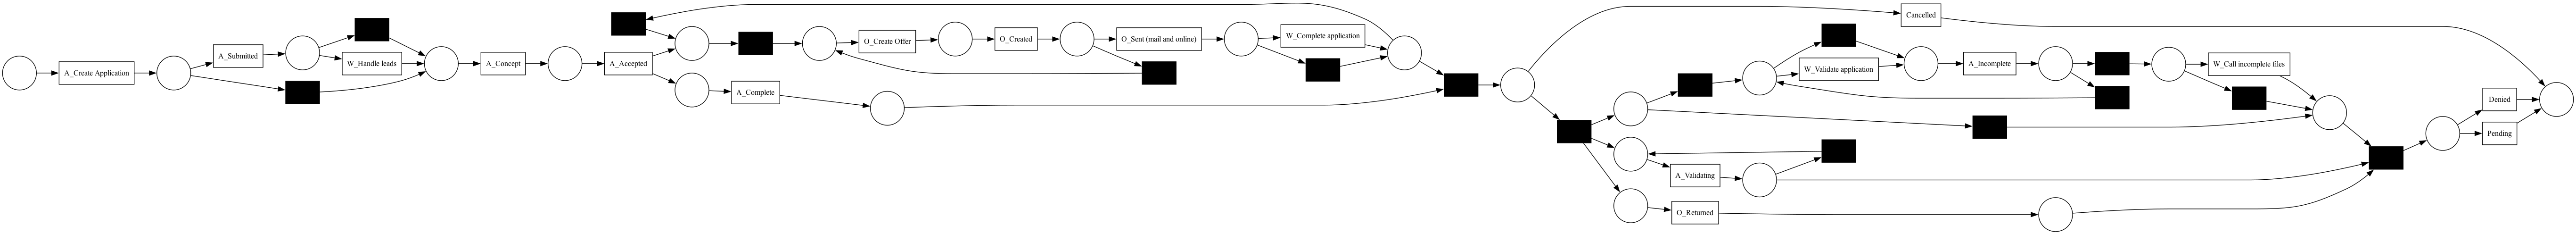

In [28]:
pm4py.view_petri_net(net)

replaying log with TBR, completed traces :: 100%|██████████| 4779/4779 [00:02<00:00, 1955.57it/s]


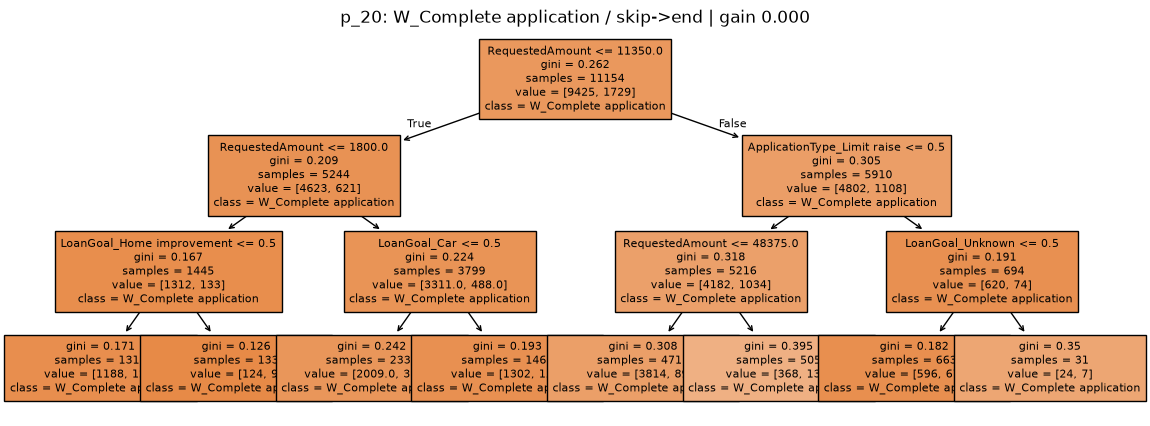

replaying log with TBR, completed traces :: 100%|██████████| 4779/4779 [00:02<00:00, 1943.75it/s]


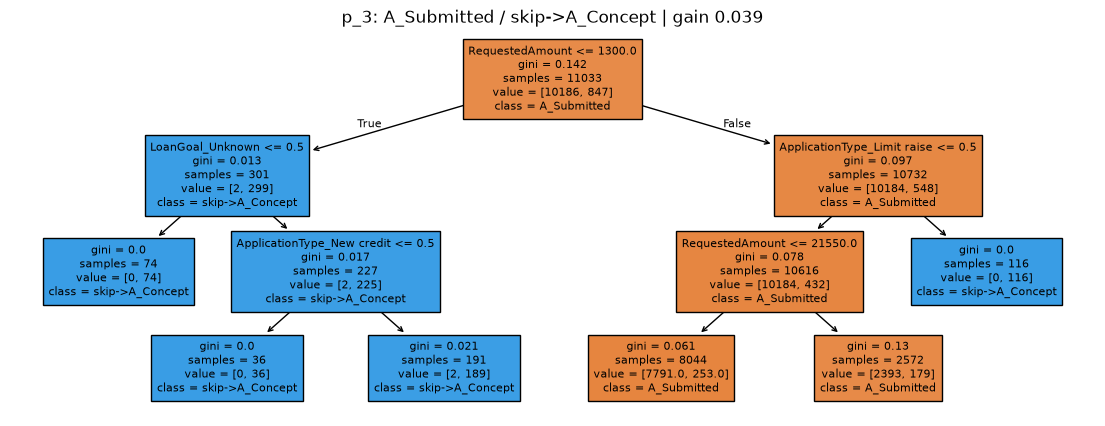

replaying log with TBR, completed traces :: 100%|██████████| 4779/4779 [00:02<00:00, 1954.88it/s]


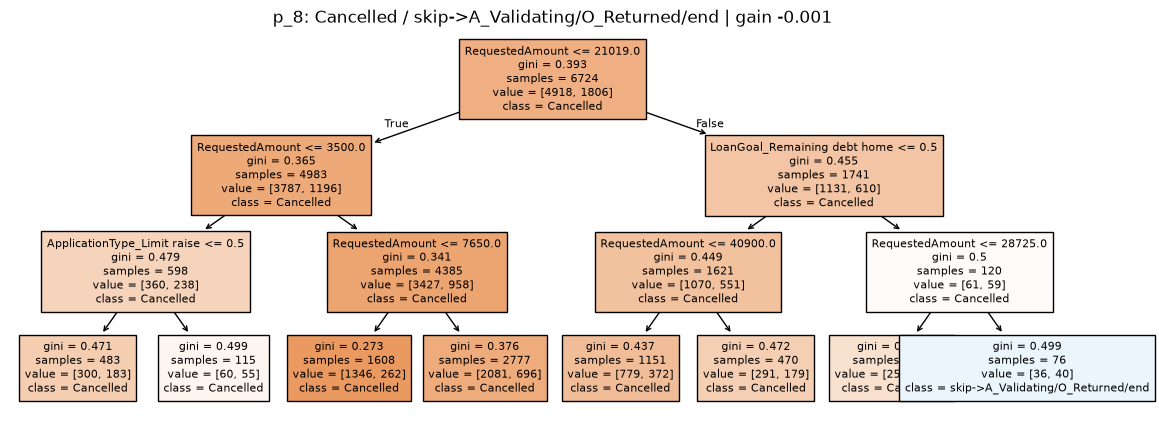

replaying log with TBR, completed traces :: 100%|██████████| 4779/4779 [00:04<00:00, 1064.84it/s]


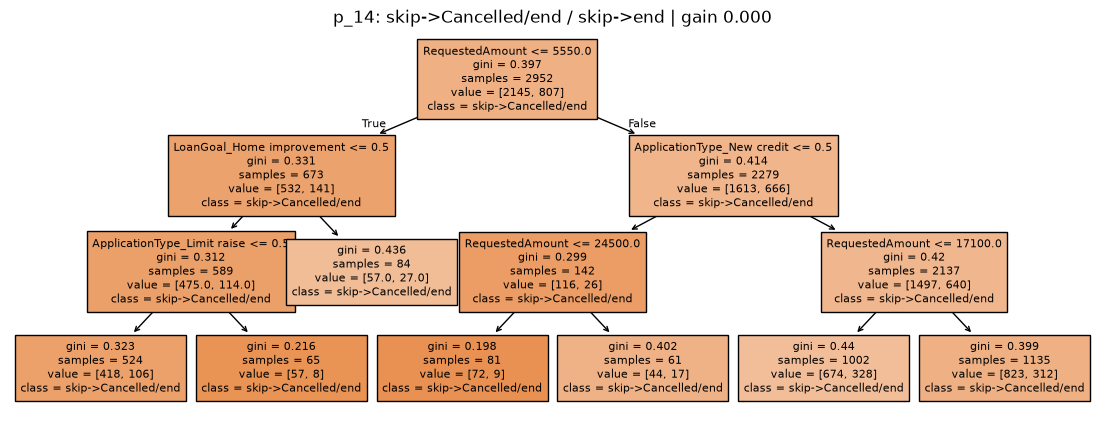

replaying log with TBR, completed traces :: 100%|██████████| 4779/4779 [00:04<00:00, 961.20it/s] 


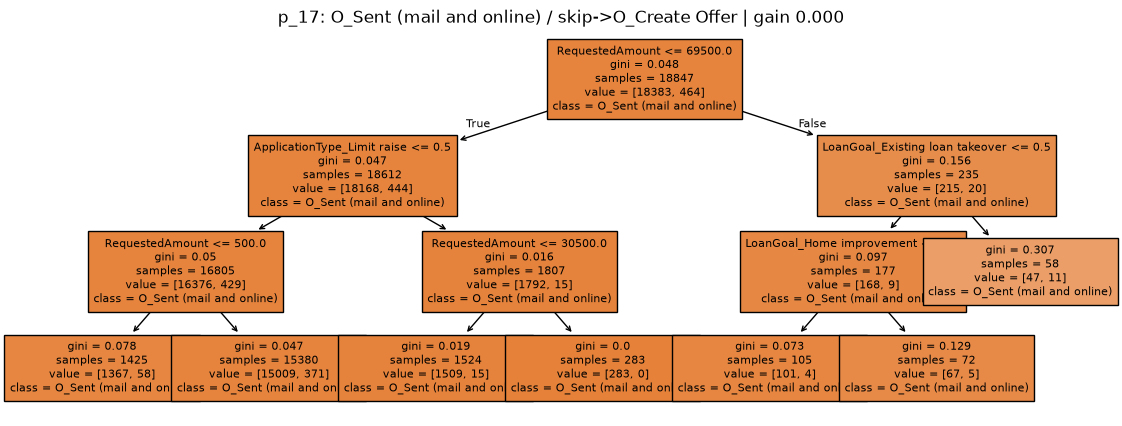

replaying log with TBR, completed traces :: 100%|██████████| 4779/4779 [00:04<00:00, 1027.80it/s]


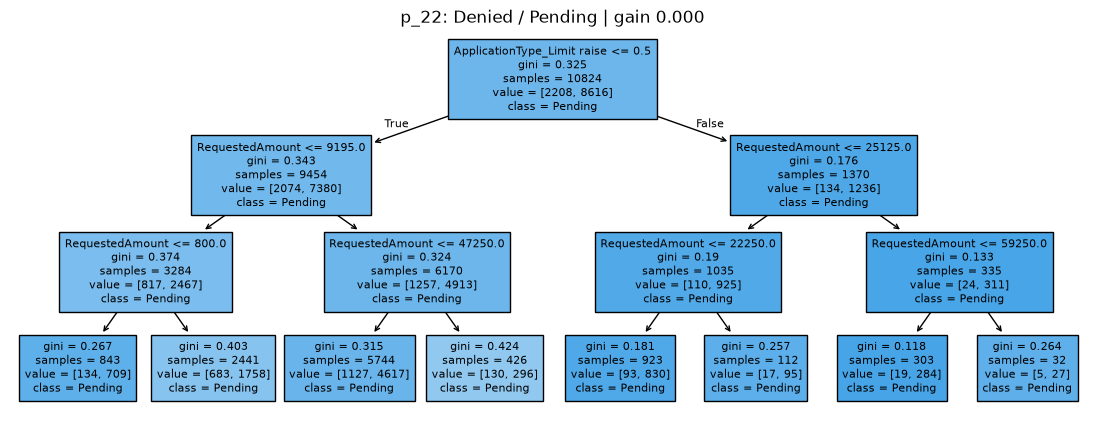

replaying log with TBR, completed traces :: 100%|██████████| 4779/4779 [00:09<00:00, 501.90it/s]


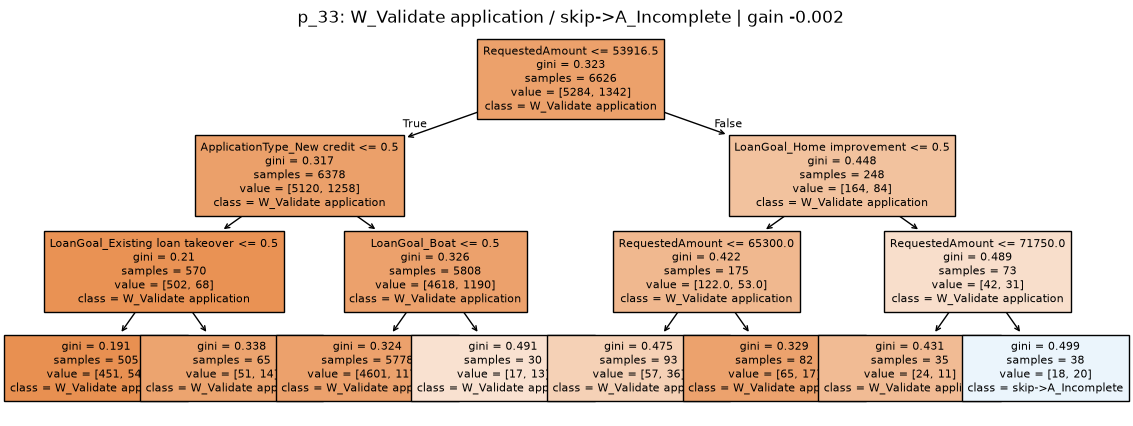

replaying log with TBR, completed traces :: 100%|██████████| 4779/4779 [00:05<00:00, 873.29it/s] 


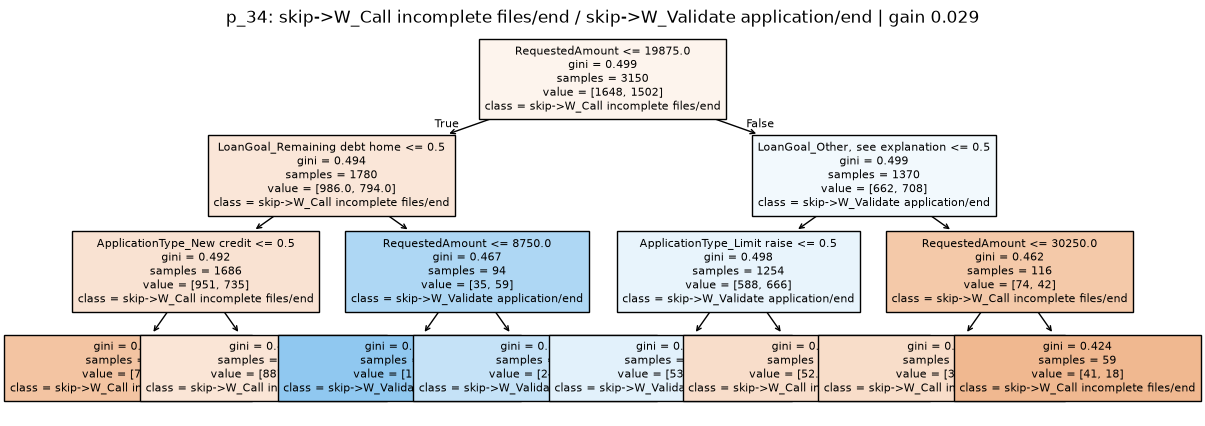

replaying log with TBR, completed traces :: 100%|██████████| 4779/4779 [00:02<00:00, 1663.57it/s]


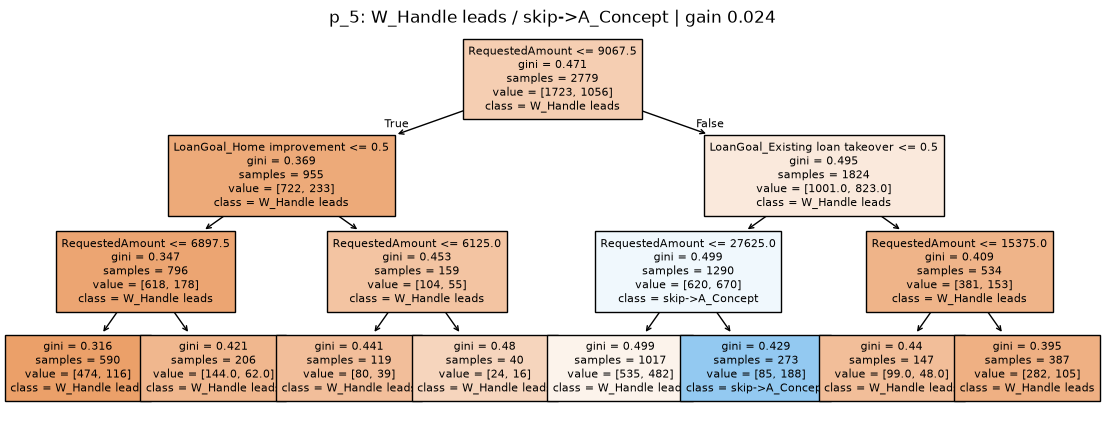

replaying log with TBR, completed traces :: 100%|██████████| 4779/4779 [00:02<00:00, 1643.26it/s]


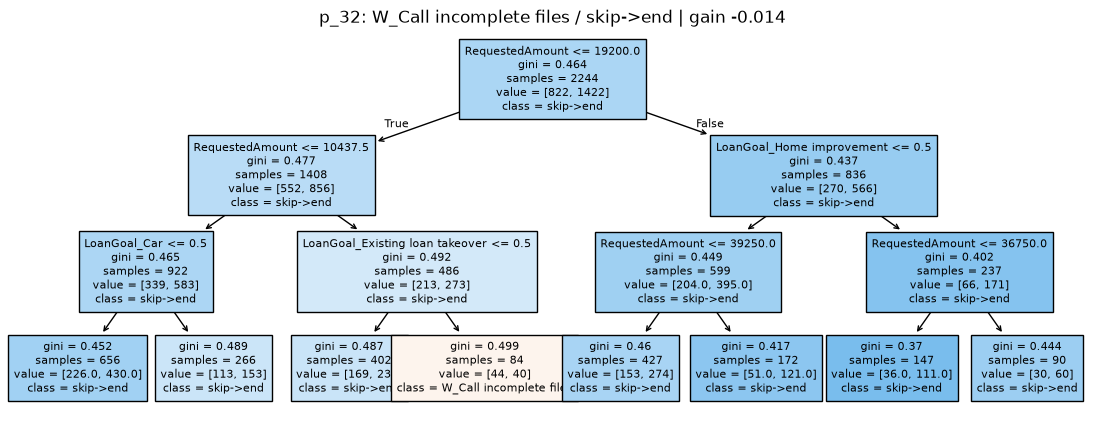

replaying log with TBR, completed traces :: 100%|██████████| 4779/4779 [00:02<00:00, 1671.06it/s]


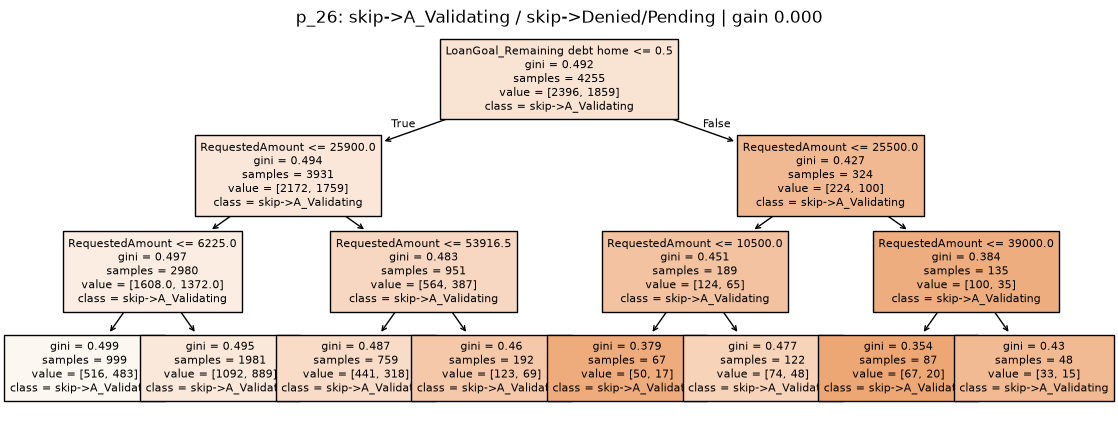

replaying log with TBR, completed traces :: 100%|██████████| 4779/4779 [00:02<00:00, 1952.41it/s]


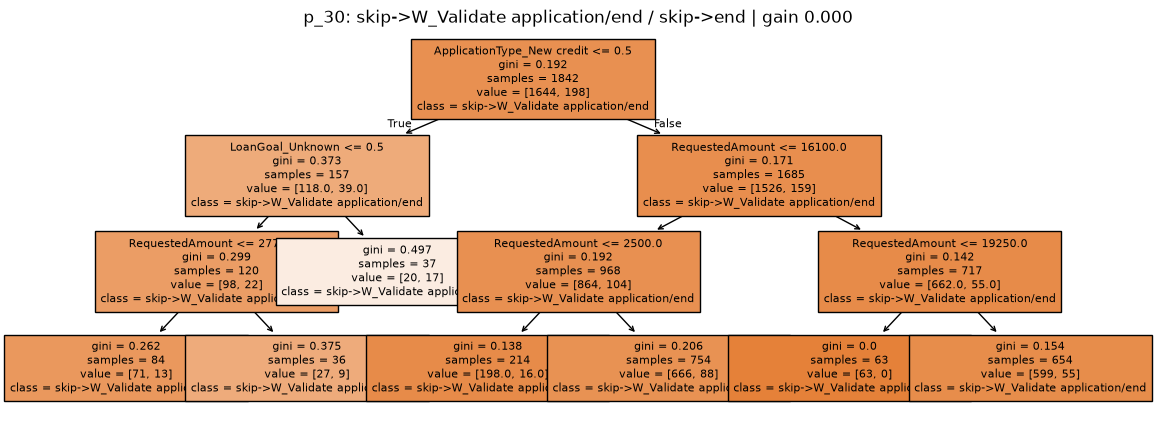

place                                                             branches     n   acc  baseline   gain
 p_20                                   W_Complete application / skip->end 22308 0.848     0.848  0.000
  p_3                                        A_Submitted / skip->A_Concept 22066 0.959     0.920  0.039
  p_8                        Cancelled / skip->A_Validating/O_Returned/end 13448 0.720     0.721 -0.001
 p_14                                      skip->Cancelled/end / skip->end  5904 0.744     0.744  0.000
 p_17                      O_Sent (mail and online) / skip->O_Create Offer 37695 0.975     0.975  0.000
 p_22                                                     Denied / Pending 21648 0.796     0.796  0.000
 p_33                          W_Validate application / skip->A_Incomplete 13252 0.801     0.803 -0.002
 p_34 skip->W_Call incomplete files/end / skip->W_Validate application/end  6301 0.545     0.516  0.029
  p_5                                     W_Handle leads / skip-

In [29]:
import pandas as pd, pm4py, matplotlib.pyplot as plt
from pm4py.algo.decision_mining import algorithm as dm
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import train_test_split

d = df.copy()
for c in ["LoanGoal", "ApplicationType", "RequestedAmount"]:
    d[c] = d["case:" + c]
attrs = ["LoanGoal", "ApplicationType", "RequestedAmount", "OfferedAmount", "NumberOfTerms", "MonthlyCost"]

def next_acts(t):
    return "/".join(sorted({a2.target.label or "end" for a in t.out_arcs for a2 in a.target.out_arcs}))

label = {t.name: t.label or f"skip->{next_acts(t)}" for t in net.transitions}
xors = [p for p in net.places if len(p.out_arcs) > 1]

rows = []
for p in xors:
    X, y, classes = dm.apply(pm4py.convert_to_event_log(d), net, im, fm, decision_point=p.name, attributes=attrs)
    names = [label.get(c, c) for c in classes]
    y = pd.Series([names[int(v)] if str(v).isdigit() else label.get(v, v) for v in y])

    keep = y.notna().values
    X, y = X[keep].fillna(0), y[keep]

    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.5, random_state=0)
    tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=30).fit(X_tr, y_tr)
    acc = tree.score(X_te, y_te)
    base = y_te.value_counts(normalize=True).max()
    rows.append({"place": p.name, "branches": " / ".join(sorted(y.unique())), "n": len(y),
                 "acc": acc, "baseline": base, "gain": acc - base})

    plt.figure(figsize=(14, 5))
    plot_tree(tree, feature_names=list(X.columns), class_names=list(tree.classes_), filled=True, fontsize=8)
    plt.title(f"{p.name}: {' / '.join(sorted(y.unique()))} | gain {acc - base:.3f}"); plt.show()

print(pd.DataFrame(rows).round(3).to_string(index=False))

Advanced task with the decision mining xor split analyse with xgboost


replaying log with TBR, completed traces :: 100%|██████████| 4779/4779 [00:02<00:00, 1813.09it/s]


p_22 | decisions: 21648 | share Denied: 0.204
accuracy: 0.796 | baseline: 0.796 | AUC: 0.682


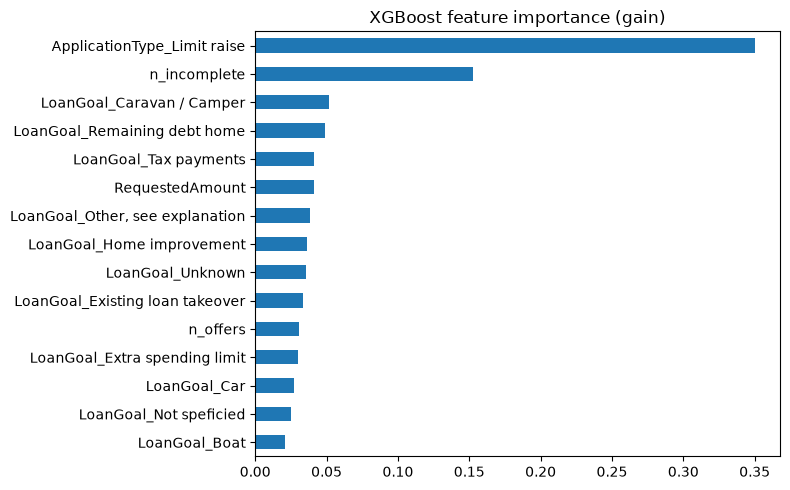

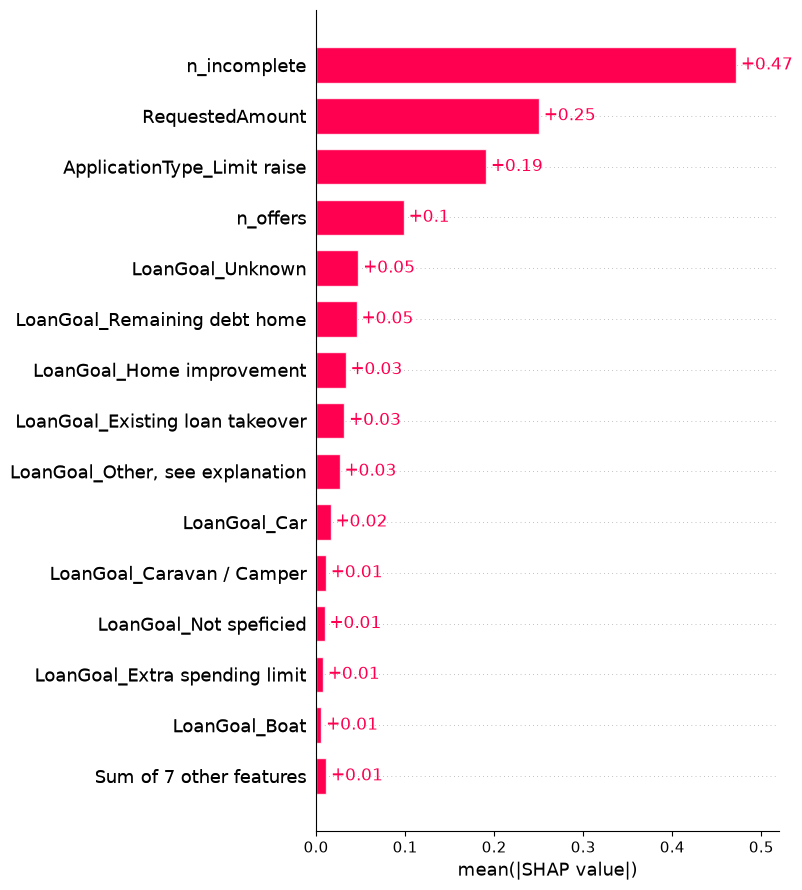

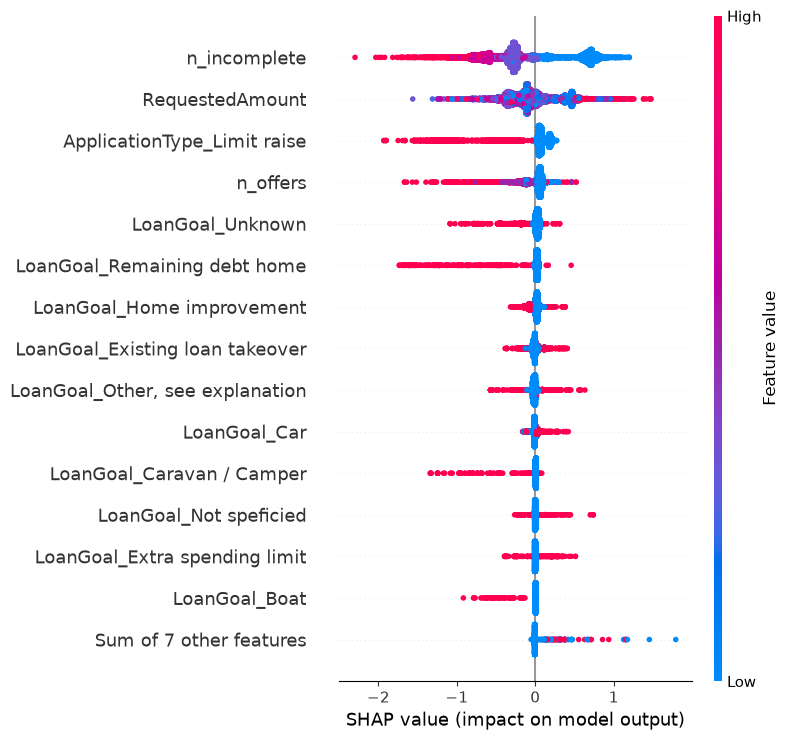

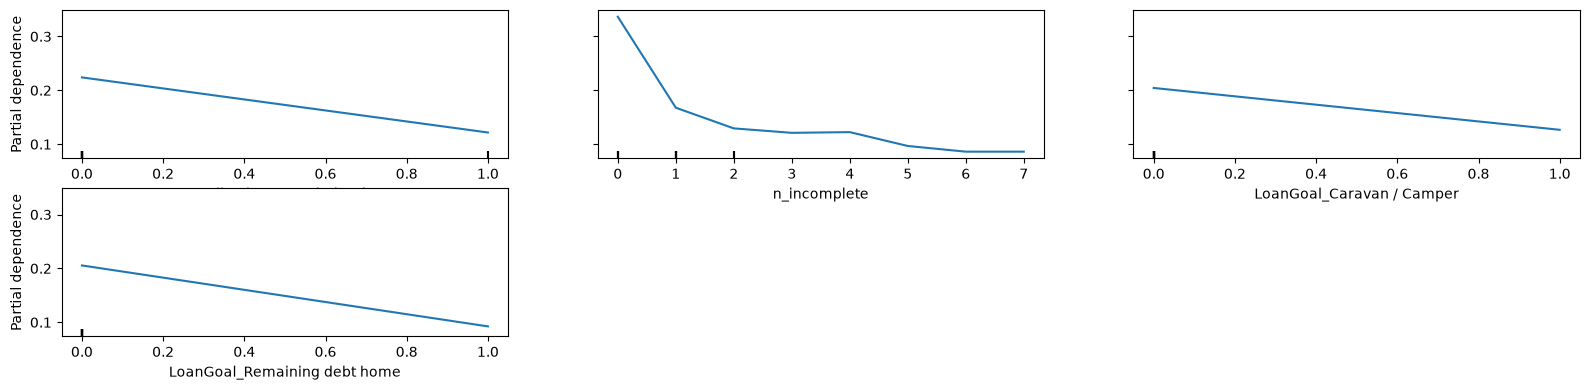

In [ ]:
import numpy as np, shap, xgboost as xgb
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.inspection import PartialDependenceDisplay

#d["n_offers"] = d[act].eq("O_Create Offer").groupby(d[cid]).cumsum()
#d["n_incomplete"] = d[act].eq("A_Incomplete").groupby(d[cid]).cumsum()
#feats = attrs + ["n_offers", "n_incomplete"]

# credit decision = the XOR with the branches Pending and Denied
credit = next(p for p in xors if {label[a.target.name] for a in p.out_arcs} == {"Pending", "Denied"})
X, y, classes = dm.apply(pm4py.convert_to_event_log(d), net, im, fm, decision_point=credit.name, attributes=feats)
names = [label.get(c, c) for c in classes]
y = pd.Series([names[int(v)] if str(v).isdigit() else label.get(v, v) for v in y])
keep = y.notna().values
X, y = X[keep].fillna(0).astype(float), (y[keep] == "Denied").astype(int)
print(credit.name, "| decisions:", len(y), "| share Denied:", round(y.mean(), 3))

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=42, stratify=y)

# xgboost
model = xgb.XGBClassifier(n_estimators=400, max_depth=5, learning_rate=0.05, random_state=42)
model.fit(X_train, y_train)
prob = model.predict_proba(X_test)[:, 1]
print("accuracy:", round(accuracy_score(y_test, prob > 0.5), 3),
      "| baseline:", round(1 - y_test.mean(), 3),
      "| AUC:", round(roc_auc_score(y_test, prob), 3))

# 1) feature importance
imp = pd.Series(model.feature_importances_, index=X.columns).sort_values()
imp.tail(15).plot.barh(figsize=(8, 5), title="XGBoost feature importance (gain)")
plt.tight_layout(); plt.savefig("xgb_importance.png", dpi=200); plt.show()

# 2) shap
sv = shap.TreeExplainer(model)(X_test)
shap.plots.bar(sv, max_display=15, show=False)
plt.tight_layout(); plt.savefig("shap_bar.png", dpi=200); plt.show()
shap.plots.beeswarm(sv, max_display=15, show=False)
plt.tight_layout(); plt.savefig("shap_beeswarm.png", dpi=200); plt.show()

# 3) pdp for the 4 most important features
top = list(imp.sort_values(ascending=False).index[:4])
fig, ax = plt.subplots(figsize=(16, 4))
PartialDependenceDisplay.from_estimator(model, X_test, top, ax=ax)
plt.tight_layout(); plt.savefig("pdp.png", dpi=200); plt.show()

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

y_pred = (prob >= 0.5).astype(int)
cm = confusion_matrix(y_test, y_pred)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.81      0.98      0.88      8615
           1       0.51      0.10      0.16      2209

    accuracy                           0.80     10824
   macro avg       0.66      0.54      0.52     10824
weighted avg       0.75      0.80      0.74     10824



              precision    recall  f1-score   support

           0       0.86      0.82      0.84      5168
           1       0.33      0.41      0.37      1126

    accuracy                           0.75      6294
   macro avg       0.60      0.61      0.60      6294
weighted avg       0.77      0.75      0.76      6294



XGBoost on the whole Data set

cases: 20980 | share Denied: 0.179
AUC: 0.762
              precision    recall  f1-score   support

     Pending       0.91      0.77      0.83      5168
      Denied       0.38      0.66      0.48      1126

    accuracy                           0.75      6294
   macro avg       0.65      0.71      0.66      6294
weighted avg       0.82      0.75      0.77      6294



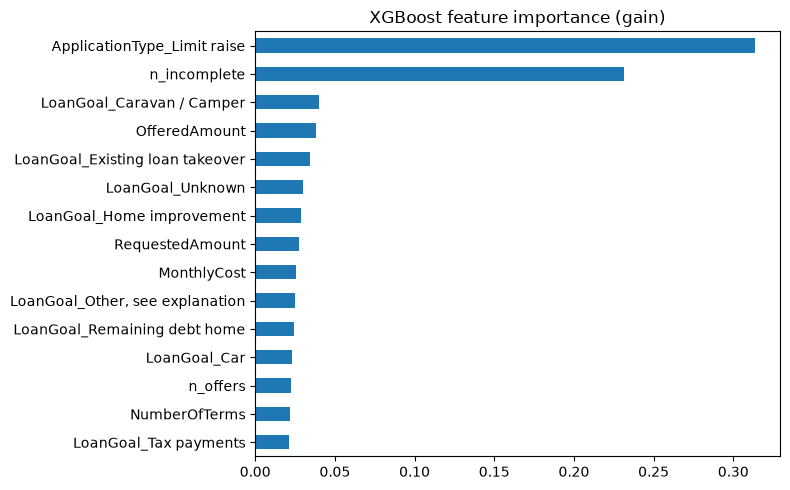

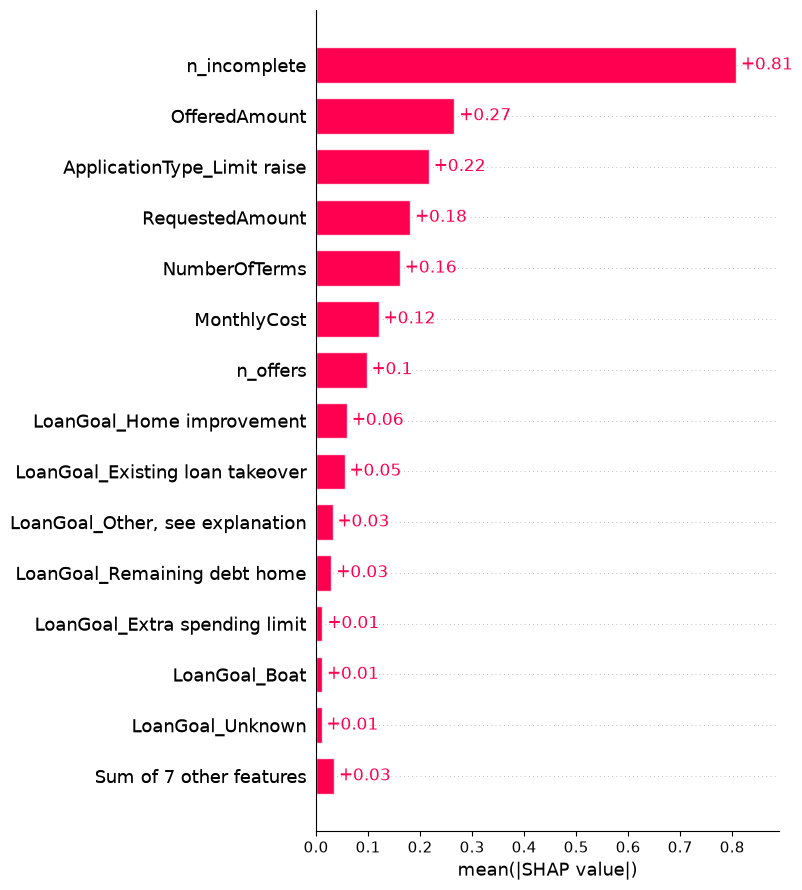

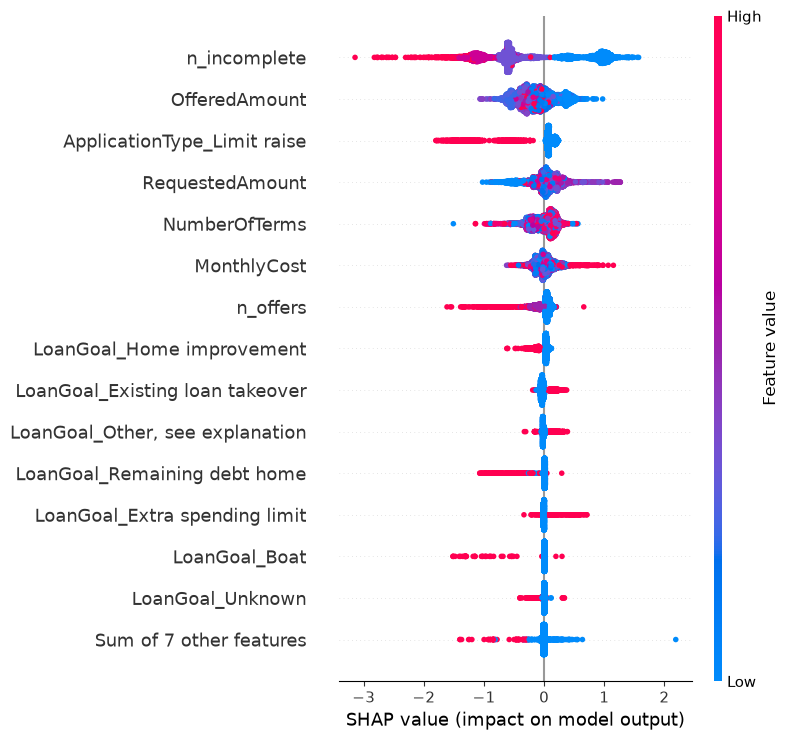

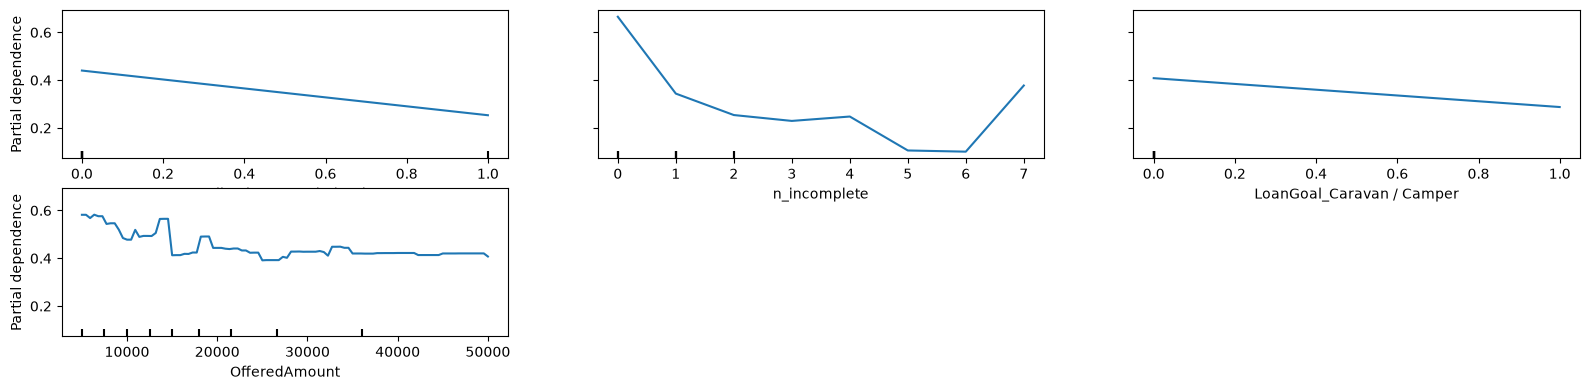

In [52]:
import numpy as np, shap, xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, classification_report
from sklearn.inspection import PartialDependenceDisplay

# one row per case: outcome, case attributes, first offer, counters
outcome = df.groupby(cid)[act].last()
cases = outcome[outcome.isin(["Pending", "Denied"])].to_frame("outcome")

first = log[log[cid].isin(cases.index)].drop_duplicates(cid).set_index(cid)
cases["LoanGoal"] = first["case:LoanGoal"]
cases["ApplicationType"] = first["case:ApplicationType"]
cases["RequestedAmount"] = first["case:RequestedAmount"]

offers = log[log[act] == "O_Create Offer"].drop_duplicates(cid).set_index(cid)
for c in ["OfferedAmount", "NumberOfTerms", "MonthlyCost"]:
    cases[c] = offers[c]

raw = log[log[cid].isin(cases.index)]
cases["n_offers"] = raw[raw[act] == "O_Create Offer"].groupby(cid).size()
cases["n_incomplete"] = raw[raw[act] == "A_Incomplete"].groupby(cid).size()
cases = cases.fillna({"n_offers": 0, "n_incomplete": 0})

X = pd.get_dummies(cases.drop(columns="outcome")).astype(float)
y = (cases["outcome"] == "Denied").astype(int)
print("cases:", len(y), "| share Denied:", round(y.mean(), 3))

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# xgboost, Denied weighted up because it is the minority
model = xgb.XGBClassifier(n_estimators=500, max_depth=4, learning_rate=0.05, random_state=42,
                          scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum())
model.fit(X_train, y_train)
prob = model.predict_proba(X_test)[:, 1]
print("AUC:", round(roc_auc_score(y_test, prob), 3))
print(classification_report(y_test, prob > 0.5, target_names=["Pending", "Denied"]))

# 1) feature importance
imp = pd.Series(model.feature_importances_, index=X.columns).sort_values()
imp.tail(15).plot.barh(figsize=(8, 5), title="XGBoost feature importance (gain)")
plt.tight_layout(); plt.savefig("xgb_importance.png", dpi=200); plt.show()

# 2) shap
sv = shap.TreeExplainer(model)(X_test)
shap.plots.bar(sv, max_display=15, show=False)
plt.tight_layout(); plt.savefig("shap_bar.png", dpi=200); plt.show()
shap.plots.beeswarm(sv, max_display=15, show=False)
plt.tight_layout(); plt.savefig("shap_beeswarm.png", dpi=200); plt.show()

# 3) pdp for the 4 most important features
top = list(imp.sort_values(ascending=False).index[:4])
fig, ax = plt.subplots(figsize=(16, 4))
PartialDependenceDisplay.from_estimator(model, X_test, top, ax=ax)
plt.tight_layout(); plt.savefig("pdp.png", dpi=200); plt.show()

n_incomplete                   0.807
OfferedAmount                  0.266
ApplicationType_Limit raise    0.217
RequestedAmount                0.181
NumberOfTerms                  0.161
MonthlyCost                    0.120
n_offers                       0.097
LoanGoal_Home improvement      0.059


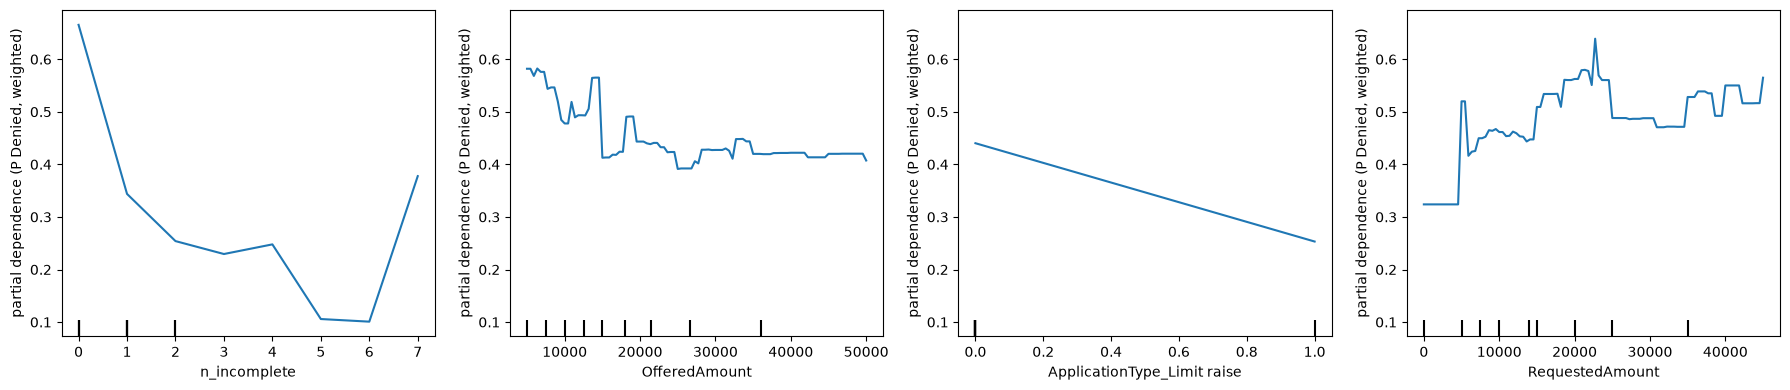

In [53]:
shap_rank = pd.Series(np.abs(sv.values).mean(axis=0), index=X.columns).sort_values(ascending=False)
top = list(shap_rank.index[:4])
print(shap_rank.head(8).round(3).to_string())

fig, ax = plt.subplots(1, 4, figsize=(18, 4))
PartialDependenceDisplay.from_estimator(model, X_test, top, ax=ax)
for a, f in zip(ax, top):
    a.set_xlabel(f); a.set_ylabel("partial dependence (P Denied, weighted)")
plt.tight_layout(); plt.savefig("pdp.png", dpi=200); plt.show()